# 4. Twenty-seven seasons: how fantasy football changed, and what never did

Every regular season nflverse covers, 1999-2025: about 144,000 player-games. Four questions:

1. How has the source of fantasy points shifted between positions?
2. Do the findings from notebooks 2-3 hold in every era, or just recently?
3. When do players peak and decline (aging curves)?
4. Would a model trained on decades of history beat one trained on three seasons?

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fantasy.data import ALL_SEASONS, SEASONS, load_player_weeks, load_games
from fantasy.features import FEATURES, TARGET, build_features, model_sample, mingus_projection
from fantasy import plots as P

P.use_style()
pd.set_option("display.precision", 3)
from fantasy.data import load_birth_dates
from fantasy.evaluate import pairwise_accuracy

In [2]:
df = pd.read_parquet("../data/features.parquet")
players = load_player_weeks(ALL_SEASONS)
seasons = (players.groupby(["player_id", "season", "position"])
           .agg(games=(TARGET, "size"), points=(TARGET, "sum"), carries=("carries", "sum"),
                receptions=("receptions", "sum"), tds=("touch_tds", "sum"))
           .reset_index())
seasons["ppg"] = seasons.points / seasons.games
print(f"{len(players):,} player-games, {len(seasons):,} player-seasons, {players.season.nunique()} seasons")

143,680 player-games, 14,776 player-seasons, 27 seasons


## 1. Where fantasy points come from

Take the top 150 fantasy scorers each season (roughly every startable player in a 12-team league) and split
their points by position.

In [3]:
top = seasons.sort_values("points", ascending=False).groupby("season").head(150)
share = (top.groupby(["season", "position"]).points.sum() / top.groupby("season").points.sum()).unstack() * 100
share.loc[[1999, 2005, 2010, 2015, 2020, 2025]].round(1)

position,QB,RB,TE,WR
season,,,,
1999,20.7,25.5,6.2,47.6
2005,18.1,29.6,9.4,42.8
2010,20.8,27.2,11.0,41.0
2015,24.8,24.8,12.1,38.3
2020,26.3,24.0,10.2,39.5
2025,25.1,29.0,12.5,33.4


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/07_position_share.png')

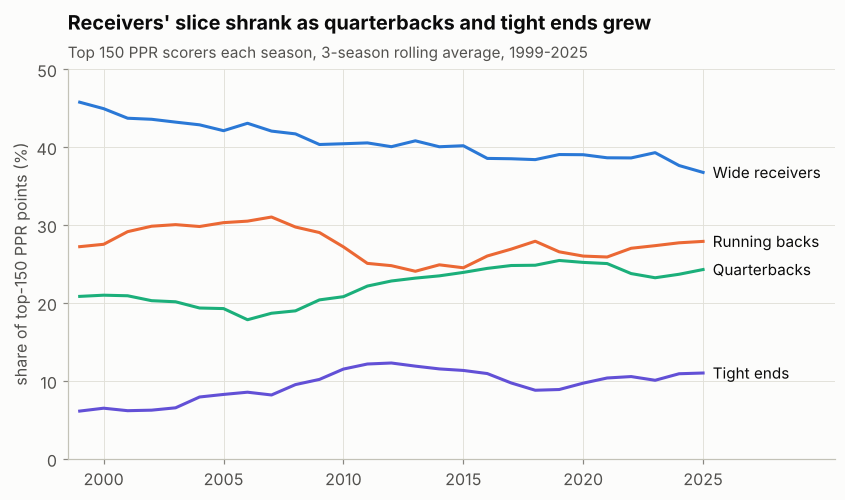

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colors = {"WR": P.BLUE, "RB": P.ORANGE, "QB": P.AQUA, "TE": P.VIOLET}
names = {"WR": "Wide receivers", "RB": "Running backs", "QB": "Quarterbacks", "TE": "Tight ends"}
smooth = share.rolling(3, center=True, min_periods=2).mean()  # 3-season average; single years are noisy
for pos, color in colors.items():
    ax.plot(smooth.index, smooth[pos], color=color)
    ax.text(smooth.index[-1] + 0.4, smooth[pos].iloc[-1], names[pos], color=P.INK, va="center", fontsize=10)
ax.set_xlim(1998.5, 2030.5)
ax.set_xticks(range(2000, 2026, 5))
ax.set_ylim(0, 50)
ax.set_ylabel("share of top-150 PPR points (%)")
ax.set_title("Receivers' slice shrank as quarterbacks and tight ends grew", pad=26)
P.subtitle(ax, "Top 150 PPR scorers each season, 3-season rolling average, 1999-2025")
P.save(fig, "07_position_share")

On a 3-season average, wide receivers went from about 46% of top-150 fantasy points to about 37% (33% in 2025 alone).
Quarterbacks (more of them run) and tight ends took most of the difference.

### The workhorse running back nearly vanished, then came back a little

PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/08_workhorse_rbs.png')

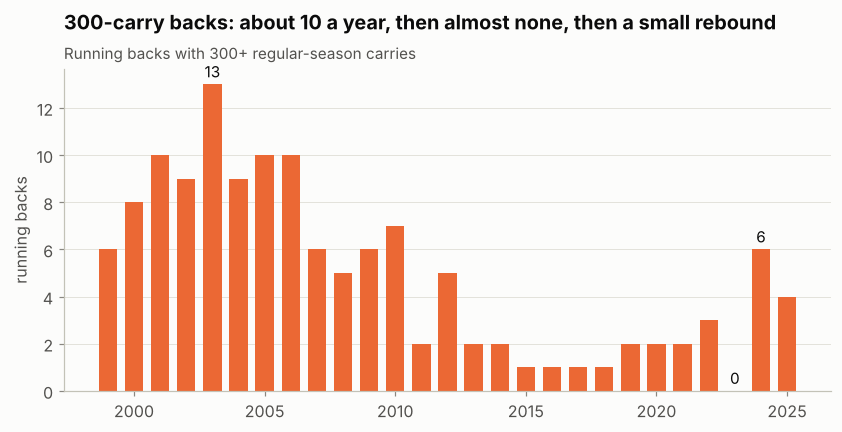

In [5]:
workhorses = (seasons[(seasons.position == "RB") & (seasons.carries >= 300)]
              .groupby("season").size().reindex(ALL_SEASONS, fill_value=0))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(workhorses.index, workhorses.values, width=0.7, color=P.ORANGE)
for yr in [2003, 2023, 2024]:
    ax.text(yr, workhorses[yr] + 0.3, str(workhorses[yr]), ha="center", color=P.INK, fontsize=10)
ax.grid(axis="x", visible=False)
ax.set_ylabel("running backs")
ax.set_title("300-carry backs: about 10 a year, then almost none, then a small rebound", pad=26)
P.subtitle(ax, "Running backs with 300+ regular-season carries")
P.save(fig, "08_workhorse_rbs")

## 2. Season average beats recent form, in every era

Notebook 2 showed the full-season average out-predicting the last three games and the last game for 2021-2025.
Is that a quirk of the modern game? Same test, every season:

In [6]:
sample = model_sample(df)
by_season = sample.groupby("season").apply(lambda d: pd.Series(
    {label: d[c].corr(d[TARGET]) for c, label in
     [("avg_season", "Season to date"), ("avg_last3", "Last 3 games"), ("last_game", "Last game")]}))
print("season avg beat last 3 games in", (by_season["Season to date"] > by_season["Last 3 games"]).sum(),
      "of", len(by_season), "seasons; last 3 beat last game in",
      (by_season["Last 3 games"] > by_season["Last game"]).sum())

season avg beat last 3 games in 27 of 27 seasons; last 3 beat last game in 27


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/09_form_every_season.png')

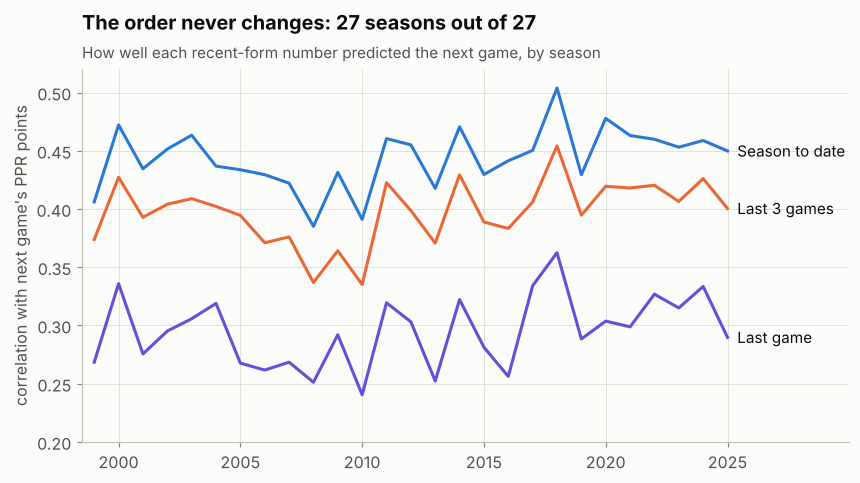

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for label, color in [("Season to date", P.BLUE), ("Last 3 games", P.ORANGE), ("Last game", P.VIOLET)]:
    ax.plot(by_season.index, by_season[label], color=color)
    ax.text(by_season.index[-1] + 0.4, by_season[label].iloc[-1], label, color=P.INK, va="center", fontsize=10)
ax.set_xlim(1998.5, 2030)
ax.set_xticks(range(2000, 2026, 5))
ax.set_ylim(0.2, 0.52)
ax.set_ylabel("correlation with next game's PPR points")
ax.set_title("The order never changes: 27 seasons out of 27", pad=26)
P.subtitle(ax, "How well each recent-form number predicted the next game, by season")
P.save(fig, "09_form_every_season")

### Touchdown spikes fade the next season too

Notebook 2 found touchdowns barely repeat week to week. Over full seasons: group RB/WR/TE seasons (10+ games, 50+ touches)
by touchdowns per touch, and see what the same players did the following year.

In [8]:
s2 = seasons[seasons.position.isin(["RB", "WR", "TE"])].copy()
s2["touches"] = s2.carries + s2.receptions
s2 = s2[(s2.games >= 10) & (s2.touches >= 50)]
s2["td_rate"] = s2.tds / s2.touches
s2["touches_pg"] = s2.touches / s2.games
nxt = s2.assign(season=s2.season - 1)[["player_id", "season", "td_rate", "touches_pg", "ppg"]]
pairs = s2.merge(nxt, on=["player_id", "season"], suffixes=("", "_next"))
pairs["fifth"] = pairs.groupby("position").td_rate.transform(lambda x: pd.qcut(x, 5, labels=False))
td = pairs.groupby("fifth")[["td_rate", "td_rate_next", "touches_pg", "touches_pg_next", "ppg", "ppg_next"]].mean()
td["n"] = pairs.groupby("fifth").size()
print(f"year-to-year correlation: TD rate {pairs.td_rate.corr(pairs.td_rate_next):.2f}, "
      f"touches per game {pairs.touches_pg.corr(pairs.touches_pg_next):.2f}")
td.round(3)

year-to-year correlation: TD rate 0.54, touches per game 0.85


,td_rate,td_rate_next,touches_pg,touches_pg_next,ppg,ppg_next,n
fifth,,,,,,,
0,0.022,0.048,8.770,8.836,9.812,11.169,417
1,0.040,0.051,9.930,9.670,11.947,12.334,412
2,0.053,0.053,10.475,10.024,13.277,12.828,414
3,0.068,0.058,10.468,10.236,14.139,13.306,414
4,0.098,0.064,9.416,9.803,14.745,13.421,412


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/10_td_regression.png')

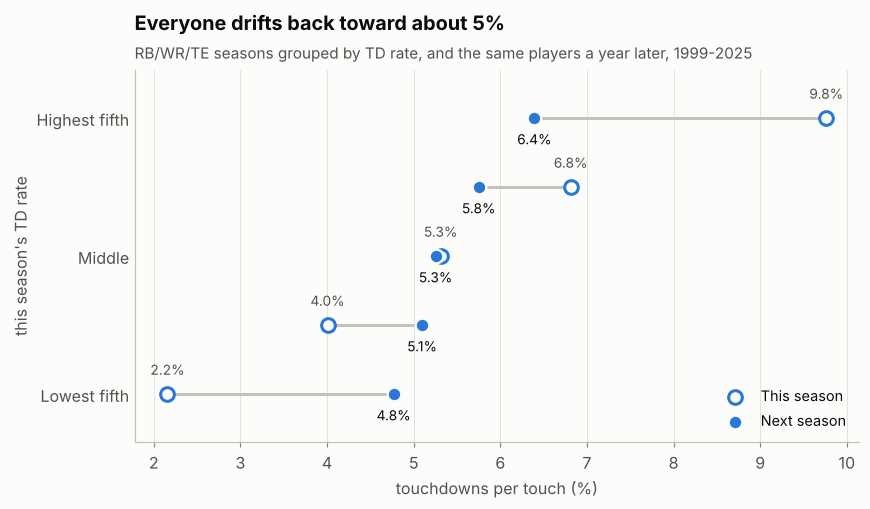

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
y = np.arange(5)
labels = ["Lowest fifth", "", "Middle", "", "Highest fifth"]
for yi, a, b in zip(y, td.td_rate * 100, td.td_rate_next * 100):
    ax.plot([a, b], [yi, yi], color=P.GREY, linewidth=2, zorder=1)
ax.scatter(td.td_rate * 100, y, s=80, color=P.SURFACE, edgecolor=P.BLUE, linewidth=2, zorder=2, label="This season")
ax.scatter(td.td_rate_next * 100, y, s=80, color=P.BLUE, edgecolor=P.SURFACE, linewidth=1.5, zorder=3, label="Next season")
for yi, a, b in zip(y, td.td_rate * 100, td.td_rate_next * 100):
    ax.text(a, yi + 0.28, f"{a:.1f}%", ha="center", color=P.INK_2, fontsize=9)
    ax.text(b, yi - 0.38, f"{b:.1f}%", ha="center", color=P.INK, fontsize=9)
ax.set_yticks(y, labels)
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.7, 4.7)
ax.grid(axis="y", visible=False)
ax.set_xlabel("touchdowns per touch (%)")
ax.set_ylabel("this season's TD rate")
ax.legend(loc="lower right", fontsize=9.5)
ax.set_title("Everyone drifts back toward about 5%", pad=26)
P.subtitle(ax, "RB/WR/TE seasons grouped by TD rate, and the same players a year later, 1999-2025")
P.save(fig, "10_td_regression")

The top fifth lose about a third of their touchdown rate the next season while their touches hold steady, so their
points per game fall. The bottom fifth gain. Volume (touches per game) carries over far better than touchdown rate.

## 3. Aging curves

The **delta method**: for every player with 8+ games in back-to-back seasons, take the change in PPR per game from
age *a* to *a + 1*, average those changes by age (weighted toward players with more games), and chain them into a curve.
Comparing each player only with themselves avoids mixing great old players with average young ones.

In [10]:
births = load_birth_dates()
ages = seasons.merge(births, on="player_id")
ages["age"] = ((pd.to_datetime(ages.season.astype(str) + "-09-01") - ages.birth_date).dt.days // 365.25).astype(int)
ages = ages[ages.games >= 8]
nxt = ages.assign(season=ages.season - 1)[["player_id", "season", "ppg", "games"]]
pairs = ages.merge(nxt, on=["player_id", "season"], suffixes=("", "_next"))
pairs["weight"] = 2 / (1 / pairs.games + 1 / pairs.games_next)  # harmonic mean of games played
pairs["delta"] = pairs.ppg_next - pairs.ppg

steps = (pairs[pairs.age.between(21, 34)].groupby(["position", "age"])
         .apply(lambda d: pd.Series({"delta": np.average(d.delta, weights=d.weight), "n": len(d)}))
         .reset_index())
steps = steps[steps.n >= 20]  # too few players at the extremes to trust the average
curves = {}
for pos, d in steps.groupby("position"):
    d = d.set_index("age").delta
    curve = pd.concat([pd.Series({d.index.min(): 0.0}), d.cumsum().set_axis(d.index + 1)])
    curves[pos] = curve - curve.max()  # 0 = that position's peak
curves = pd.DataFrame(curves)
print("peak age:", curves.idxmax().to_dict())
curves.round(2)

peak age: {'QB': 30, 'RB': 24, 'TE': 25, 'WR': 25}


,QB,RB,TE,WR
21,NaN,-3.19,-5.00,-4.46
22,-2.81,-1.97,-2.54,-2.36
23,-1.33,-0.07,-1.37,-1.14
24,-0.72,0.00,-0.43,-0.65
25,-0.69,-0.21,0.00,0.00
26,-1.22,-0.13,-0.18,-0.01
27,-0.64,-0.70,-0.48,-0.41
28,-0.66,-1.47,-0.55,-1.32
29,-0.46,-2.50,-0.69,-1.97
30,0.00,-3.80,-1.46,-3.06


PosixPath('/tmp/claude-0/-home-user-mingus/3154deef-21db-5d5f-a681-635c7f758d74/scratchpad/nfl-fantasy-analysis/reports/figures/11_aging_curves.png')

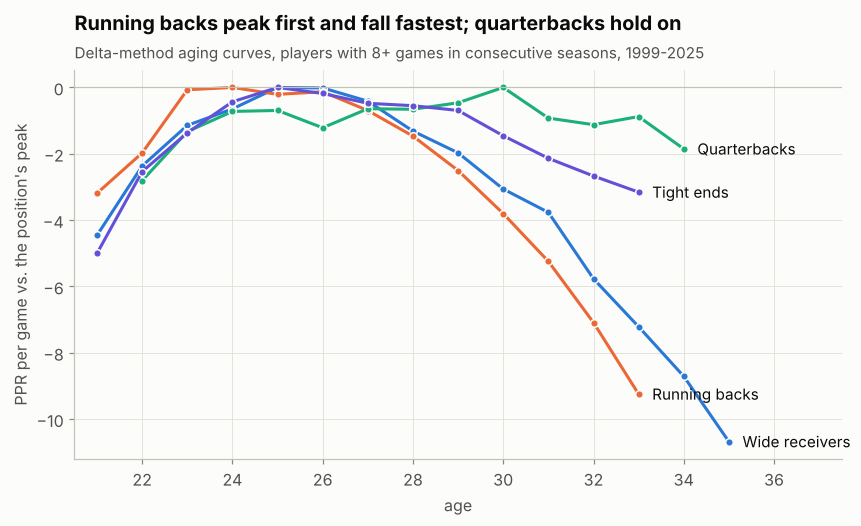

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for pos, color in colors.items():
    c = curves[pos].dropna()
    ax.plot(c.index, c.values, color=color, marker="o", markersize=5, markeredgecolor=P.SURFACE)
    ax.text(c.index[-1] + 0.3, c.iloc[-1], names[pos], color=P.INK, va="center", fontsize=10)
ax.axhline(0, color=P.GREY, linewidth=0.8)
ax.set_xlim(20.5, 37.5)
ax.set_xlabel("age")
ax.set_ylabel("PPR per game vs. the position's peak")
ax.set_title("Running backs peak first and fall fastest; quarterbacks hold on", pad=26)
P.subtitle(ax, "Delta-method aging curves, players with 8+ games in consecutive seasons, 1999-2025")
P.save(fig, "11_aging_curves")

Running backs peak at about 24, hold roughly level to 26, then lose points every year, faster than any other
position. Receivers and tight ends peak around 25-26 and decline more gradually. Quarterbacks peak around 30 and stay
close to it into their mid-30s. One caveat: players who decline sharply
tend to leave the league, so they drop out of the data. That makes every curve, especially at older ages, look gentler
than reality.

## 4. Does more history make a better model?

Same ridge model as notebook 3, same 2025 test season, but trained on longer and longer windows. Training starts no
earlier than 2009, the first season after the missing-targets gap.

In [12]:
from sklearn.compose import make_column_transformer
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sample["has_prior"] = sample.prior_season_avg.notna().astype(int)
sample["prior_fill"] = sample.prior_season_avg.fillna(sample.avg_season)
NUM = [f for f in FEATURES if f != "prior_season_avg"] + ["prior_fill", "has_prior"]
X = NUM + ["position"]
test = sample[sample.season == 2025].copy()

rows = []
for start in [2021, 2018, 2015, 2012, 2009]:
    train = sample[sample.season.between(start, 2023)]
    model = make_pipeline(make_column_transformer((StandardScaler(), NUM), (OneHotEncoder(), ["position"])),
                          RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(train[X], train[TARGET])
    test["pred"] = model.predict(test[X])
    rows.append({"training seasons": f"{start}-2023", "rows": len(train),
                 "MAE": (test.pred - test[TARGET]).abs().mean(),
                 "start/sit acc.": pairwise_accuracy(test, "pred", TARGET)})
history = pd.DataFrame(rows).set_index("training seasons")
history.round(4)

,rows,MAE,start/sit acc.
training seasons,,,
2021-2023,7894,5.674,0.655
2018-2023,15577,5.673,0.656
2015-2023,23280,5.668,0.655
2012-2023,30853,5.666,0.656
2009-2023,38186,5.670,0.655


Five times the training data, essentially the same accuracy. The limit isn't a shortage of examples: it's that
a single game is noisy (injuries, game script, a broken tackle). A few seasons are enough to learn how much weight each
signal deserves. This also suggests the relationships are stable across eras, which matches section 2.

## Takeaways

* The game changed: receivers' share of top-150 fantasy points fell from about 46% to about 37%, and 300-carry backs nearly disappeared.
* What predicts fantasy points did not change: the full season beat recent form in all 27 seasons, and touchdown
  spikes regress every year.
* Draft with age in mind: running backs decline steeply after about 26, while quarterbacks hold value into their 30s.
* More historical data doesn't improve weekly projections. Better *information* would: injuries, snap counts, depth charts.